# 07 — Grad-CAM Investigation: HAM vs BCN cross-source analysis

**Versiune v3 — gata de rulat:**
- Folosește `best.keras`
- Reface inferența cu `image_id` salvat (CSV-ul vechi nu are image_id)
- Tratează `other = MSK` în filtrare
- Ordine corectă: TFRecord parser → model → inferență → analiză

**Rulează celulele în ordine, una câte una.**

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Imports & Config

**⚠️ Verifică `TFRECORD_DIR` — ajustează dacă e altă cale.**

In [2]:
import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
from pathlib import Path

# === CONFIG ===
DRIVE_BASE   = Path('/content/drive/MyDrive/Thesis')
EFNET_DIR    = DRIVE_BASE / 'experiments' / 'efficientnetv2b0'
TIER         = 5
MODEL_DIR    = EFNET_DIR / f'tier{TIER}' / 'D_final'

# >>> AJUSTEAZĂ dacă TFRecord-urile sunt în altă parte
TFRECORD_DIR = Path("/content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords/test")

OUTPUT_DIR   = MODEL_DIR / 'gradcam_investigation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH        = MODEL_DIR / 'best.keras'
OLD_PRED_CSV      = MODEL_DIR / 'test_predictions.csv'           # CSV vechi (fără image_id)
NEW_PRED_CSV      = OUTPUT_DIR / 'test_predictions_with_ids.csv'  # CSV nou (cu image_id)

IMG_SIZE     = 224
NUM_CLASSES  = 7
CLASS_NAMES  = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
BATCH_SIZE   = 32

# Mapping pentru valorile de source — 'other' = MSK
SOURCE_MAP = {'other': 'MSK', 'MSK': 'MSK', 'HAM10000': 'HAM10000', 'BCN_20000': 'BCN_20000'}

print(f'Model:        {MODEL_PATH} (exists: {MODEL_PATH.exists()})')
print(f'Old pred CSV: {OLD_PRED_CSV} (exists: {OLD_PRED_CSV.exists()})')
print(f'TFRecord:     {TFRECORD_DIR} (exists: {TFRECORD_DIR.exists()})')
print(f'Output dir:   {OUTPUT_DIR}')

Model:        /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/best.keras (exists: True)
Old pred CSV: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/test_predictions.csv (exists: True)
TFRecord:     /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords/test (exists: True)
Output dir:   /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/gradcam_investigation


## 3. TFRecord parser + sanity check

In [3]:
FEATURE_DESCRIPTION = {
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
}


def parse_example(example_proto):
    parsed = tf.io.parse_single_example(example_proto, FEATURE_DESCRIPTION)
    image = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0  # preprocesare EfficientNetV2B0
    return {
        'image': image,
        'label': parsed['label'],
        'image_id': parsed['image_id'],
        'source': parsed['source'],
        'lesion_id': parsed['lesion_id'],
    }


def build_test_dataset():
    files = sorted(tf.io.gfile.glob(str(TFRECORD_DIR / '*.tfrec*')))
    if len(files) == 0:
        raise FileNotFoundError(f'Nu am găsit TFRecords în {TFRECORD_DIR}')
    print(f'Found {len(files)} TFRecord files')
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    return ds


# Sanity check
ds = build_test_dataset()
for ex in ds.take(1):
    print(f"\nimage:     {ex['image'].shape}, range [{tf.reduce_min(ex['image']):.3f}, {tf.reduce_max(ex['image']):.3f}]")
    print(f"label:     {ex['label'].numpy()} ({CLASS_NAMES[ex['label'].numpy()]})")
    print(f"image_id:  {ex['image_id'].numpy().decode()}")
    print(f"source:    {ex['source'].numpy().decode()}")
    print(f"lesion_id: {ex['lesion_id'].numpy().decode()}")

Found 3 TFRecord files

image:     (224, 224, 3), range [-0.913, 0.698]
label:     5 (nv)
image_id:  ISIC_0000007
source:    other
lesion_id: SYNTH_ISIC_0000007


## 4. Load best model

In [4]:
model = tf.keras.models.load_model(str(MODEL_PATH), compile=False)
print(f'Loaded: {MODEL_PATH}')
print(f'Input shape:  {model.input_shape}')
print(f'Output shape: {model.output_shape}')

print('\nTop-level layers:')
for i, layer in enumerate(model.layers):
    is_submodel = hasattr(layer, 'layers')
    print(f'  [{i}] {layer.name} ({type(layer).__name__})' + (' [SUBMODEL]' if is_submodel else ''))

Loaded: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/best.keras
Input shape:  (None, 224, 224, 3)
Output shape: (None, 7)

Top-level layers:
  [0] input_layer_1 (InputLayer)
  [1] efficientnetv2-b0 (Functional) [SUBMODEL]
  [2] global_average_pooling2d (GlobalAveragePooling2D)
  [3] dense (Dense)
  [4] batch_normalization (BatchNormalization)
  [5] dropout (Dropout)
  [6] dense_1 (Dense)
  [7] batch_normalization_1 (BatchNormalization)
  [8] dropout_1 (Dropout)
  [9] dense_2 (Dense)


## 5. Inferență cu image_id (5–10 min pe GPU)

Salvăm `image_id`, `source`, `true_label`, `pred_label`, `confidence` plus probabilitățile per clasă.  
Dacă fișierul există deja, îl încarcă direct.

In [5]:
if NEW_PRED_CSV.exists():
    print(f'Loading existing: {NEW_PRED_CSV}')
    df_pred = pd.read_csv(NEW_PRED_CSV)
else:
    print('Running inference with image_ids...')
    ds = build_test_dataset()
    ds_batched = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    all_image_ids, all_lesion_ids, all_sources = [], [], []
    all_y_true, all_y_pred, all_confidence = [], [], []
    all_probs = []

    for i, batch in enumerate(ds_batched):
        probs = model.predict(batch['image'], verbose=0)
        preds = np.argmax(probs, axis=1)
        confs = np.max(probs, axis=1)

        all_image_ids.extend([s.decode() for s in batch['image_id'].numpy()])
        all_lesion_ids.extend([s.decode() for s in batch['lesion_id'].numpy()])
        all_sources.extend([s.decode() for s in batch['source'].numpy()])
        all_y_true.extend(batch['label'].numpy().tolist())
        all_y_pred.extend(preds.tolist())
        all_confidence.extend(confs.tolist())
        all_probs.append(probs)

        if (i + 1) % 20 == 0:
            print(f'  Batch {i+1}, processed {len(all_image_ids)} images')

    all_probs = np.concatenate(all_probs, axis=0)

    df_pred = pd.DataFrame({
        'image_id': all_image_ids,
        'lesion_id': all_lesion_ids,
        'source': all_sources,
        'true_label': all_y_true,
        'pred_label': all_y_pred,
        'confidence': all_confidence,
    })
    for i, c in enumerate(CLASS_NAMES):
        df_pred[f'prob_{c}'] = all_probs[:, i]
    df_pred.to_csv(NEW_PRED_CSV, index=False)
    print(f'Saved: {NEW_PRED_CSV}')

# Coloane derivate
df_pred['true_class']    = df_pred['true_label'].map(lambda i: CLASS_NAMES[int(i)])
df_pred['pred_class']    = df_pred['pred_label'].map(lambda i: CLASS_NAMES[int(i)])
df_pred['correct']       = df_pred['true_label'] == df_pred['pred_label']
# Normalizează source: 'other' → 'MSK'
df_pred['source_clean']  = df_pred['source'].map(lambda s: SOURCE_MAP.get(s, s))

print(f'\nTotal: {len(df_pred)}')
print(f'\nValori source originale:')
print(df_pred['source'].value_counts())
print(f'\nValori source normalizate:')
print(df_pred['source_clean'].value_counts())
print(f'\nAccuracy per source (clean):')
print(df_pred.groupby('source_clean')['correct'].agg(['mean', 'count']).round(4))

Running inference with image_ids...
Found 3 TFRecord files
  Batch 20, processed 640 images
  Batch 40, processed 1280 images
  Batch 60, processed 1920 images
Saved: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/D_final/gradcam_investigation/test_predictions_with_ids.csv

Total: 2513

Valori source originale:
source
BCN_20000    1236
HAM10000      956
other         234
MSK            87
Name: count, dtype: int64

Valori source normalizate:
source_clean
BCN_20000    1236
HAM10000      956
MSK           321
Name: count, dtype: int64

Accuracy per source (clean):
                mean  count
source_clean               
BCN_20000     0.6011   1236
HAM10000      0.8065    956
MSK           0.6916    321


## 6. Sanity check vs CSV vechi

Vrem să confirmăm că accuracy per source se potrivește între CSV-ul vechi și cel nou (±1%).

In [6]:
if OLD_PRED_CSV.exists():
    df_old = pd.read_csv(OLD_PRED_CSV)
    df_old['correct']      = df_old['y_true'] == df_old['y_pred']
    df_old['source_clean'] = df_old['source'].map(lambda s: SOURCE_MAP.get(s, s))

    print(f'Vechi: {len(df_old)} rows | Nou: {len(df_pred)} rows')
    print(f'\nVechi — accuracy per source:')
    print(df_old.groupby('source_clean')['correct'].agg(['mean', 'count']).round(4))
    print(f'\nNou — accuracy per source:')
    print(df_pred.groupby('source_clean')['correct'].agg(['mean', 'count']).round(4))
    print('\nDacă numerele se potrivesc → totul OK, mergem mai departe.')
else:
    print('Nu există CSV vechi pentru sanity check, sărim.')

Vechi: 2513 rows | Nou: 2513 rows

Vechi — accuracy per source:
                mean  count
source_clean               
BCN_20000     0.5995   1236
HAM10000      0.8065    956
MSK           0.6885    321

Nou — accuracy per source:
                mean  count
source_clean               
BCN_20000     0.6011   1236
HAM10000      0.8065    956
MSK           0.6916    321

Dacă numerele se potrivesc → totul OK, mergem mai departe.


## 7. Selecție candidați Grad-CAM

- **Set A**: HAM10000 corecte (modelul reușește pe HAM)
- **Set B**: BCN_20000 incorecte cu confidence mare (model încrezător dar greșește)
- **Set C**: BCN_20000 corecte (control: modelul reușește pe BCN)

In [7]:
N_PER_CLASS_PER_SET = 3


def select_candidates(df, source, correct, n=N_PER_CLASS_PER_SET):
    """Top-N per clasă, filtrate după sursă (folosim source_clean)."""
    sub = df[(df['source_clean'] == source) & (df['correct'] == correct)].copy()
    selected = (sub.sort_values('confidence', ascending=False)
                   .groupby('true_class', group_keys=False)
                   .head(n))
    return selected.sort_values(['true_class', 'confidence'], ascending=[True, False])


set_A = select_candidates(df_pred, 'HAM10000',  correct=True)
set_B = select_candidates(df_pred, 'BCN_20000', correct=False)
set_C = select_candidates(df_pred, 'BCN_20000', correct=True)

print('=== Set A: HAM10000 correct (high conf) ===')
print(set_A[['true_class', 'pred_class', 'image_id', 'confidence']].to_string(index=False))
print('\n=== Set B: BCN_20000 INCORRECT (high conf — confidently wrong) ===')
print(set_B[['true_class', 'pred_class', 'image_id', 'confidence']].to_string(index=False))
print('\n=== Set C: BCN_20000 correct (high conf — control) ===')
print(set_C[['true_class', 'pred_class', 'image_id', 'confidence']].to_string(index=False))

set_A.to_csv(OUTPUT_DIR / 'set_A_HAM_correct.csv', index=False)
set_B.to_csv(OUTPUT_DIR / 'set_B_BCN_incorrect.csv', index=False)
set_C.to_csv(OUTPUT_DIR / 'set_C_BCN_correct.csv', index=False)

=== Set A: HAM10000 correct (high conf) ===
true_class pred_class     image_id  confidence
     akiec      akiec ISIC_0030827    0.887954
     akiec      akiec ISIC_0026927    0.842540
     akiec      akiec ISIC_0026525    0.563860
       bcc        bcc ISIC_0028556    0.961291
       bcc        bcc ISIC_0027966    0.947108
       bcc        bcc ISIC_0024448    0.941759
       bkl        bkl ISIC_0026511    0.988228
       bkl        bkl ISIC_0033446    0.977148
       bkl        bkl ISIC_0030124    0.974811
        df         df ISIC_0025223    0.999981
        df         df ISIC_0025771    0.999953
        df         df ISIC_0024994    0.999878
       mel        mel ISIC_0033394    0.870738
       mel        mel ISIC_0024545    0.848311
       mel        mel ISIC_0034233    0.829606
        nv         nv ISIC_0031047    1.000000
        nv         nv ISIC_0026041    1.000000
        nv         nv ISIC_0027449    1.000000
      vasc       vasc ISIC_0026092    0.999864
      vasc      

## 8. Build Grad-CAM model

Construiește un model funcțional care expune simultan feature maps (ultimul conv) și predictions.

In [8]:
def build_gradcam_model(model, target_layer_names=('top_activation', 'top_conv')):
    # Caută backbone-ul (submodel)
    backbone = None
    for layer in model.layers:
        if hasattr(layer, 'layers') and 'efficientnet' in layer.name.lower():
            backbone = layer
            break

    if backbone is None:
        # Caută direct
        target = None
        for name in target_layer_names:
            try:
                target = model.get_layer(name)
                break
            except ValueError:
                continue
        if target is None:
            for layer in reversed(model.layers):
                if isinstance(layer, tf.keras.layers.Conv2D):
                    target = layer
                    break
        print(f'Target layer (direct): {target.name}')
        return tf.keras.Model(inputs=model.input, outputs=[target.output, model.output])

    print(f'Backbone: {backbone.name}')
    target = None
    for name in target_layer_names:
        try:
            target = backbone.get_layer(name)
            print(f'Target layer in backbone: {target.name}')
            break
        except ValueError:
            continue
    if target is None:
        for layer in reversed(backbone.layers):
            if isinstance(layer, tf.keras.layers.Conv2D):
                target = layer
                print(f'Target layer (fallback last Conv2D): {target.name}')
                break

    # Reconstruim funcțional: input → backbone (cu fm extras) → head
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    feature_extractor = tf.keras.Model(
        inputs=backbone.input,
        outputs=[backbone.get_layer(target.name).output, backbone.output]
    )
    feature_maps, backbone_out = feature_extractor(inputs)

    backbone_idx = next(i for i, l in enumerate(model.layers) if l is backbone)
    x = backbone_out
    for layer in model.layers[backbone_idx + 1:]:
        x = layer(x)

    return tf.keras.Model(inputs=inputs, outputs=[feature_maps, x])


grad_model = build_gradcam_model(model)

# Sanity test
for ex in build_test_dataset().take(1):
    img_batch = tf.expand_dims(ex['image'], 0)
    fm, preds = grad_model(img_batch, training=False)
    print(f'\nFeature maps shape: {fm.shape}')
    print(f'Predictions shape:  {preds.shape}')
    print(f'Pred class:         {CLASS_NAMES[int(tf.argmax(preds[0]))]}')
    print(f'True class:         {CLASS_NAMES[ex["label"].numpy()]}')
    # Verifică că predicțiile noului model coincid cu modelul original
    preds_orig = model(img_batch, training=False)
    print(f'Match cu model original: {np.allclose(preds.numpy(), preds_orig.numpy(), atol=1e-5)}')

Backbone: efficientnetv2-b0
Target layer in backbone: top_activation
Found 3 TFRecord files

Feature maps shape: (1, 7, 7, 1280)
Predictions shape:  (1, 7)
Pred class:         nv
True class:         nv
Match cu model original: True


## 9. compute_gradcam

Found 3 TFRecord files


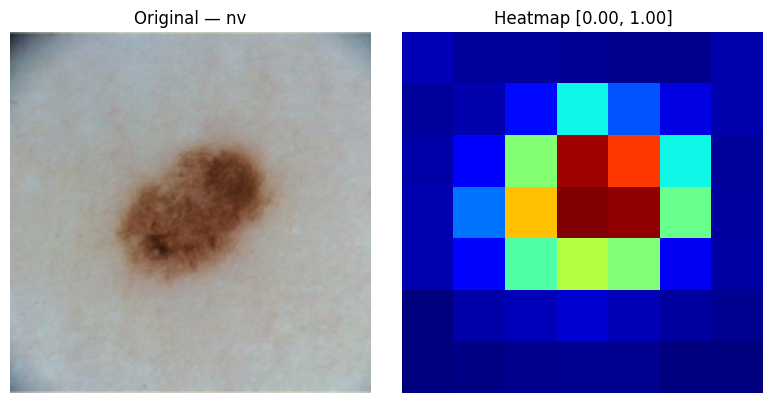

In [9]:
def compute_gradcam(image, target_class_idx):
    img_batch = tf.expand_dims(image, 0)
    with tf.GradientTape() as tape:
        feature_maps, preds = grad_model(img_batch, training=False)
        class_score = preds[:, target_class_idx]
    grads = tape.gradient(class_score, feature_maps)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    fmap = feature_maps[0]
    heatmap = tf.reduce_sum(fmap * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    max_val = tf.reduce_max(heatmap)
    if max_val > 0:
        heatmap = heatmap / max_val
    return heatmap.numpy()


# Sanity vizual
for ex in build_test_dataset().take(1):
    hm = compute_gradcam(ex['image'], ex['label'].numpy())
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(((ex['image'].numpy() + 1) * 127.5).astype(np.uint8))
    axes[0].set_title(f"Original — {CLASS_NAMES[ex['label'].numpy()]}")
    axes[0].axis('off')
    axes[1].imshow(hm, cmap='jet')
    axes[1].set_title(f'Heatmap [{hm.min():.2f}, {hm.max():.2f}]')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

## 10. Lookup imagini după image_id

Iterăm o singură dată prin testset și păstrăm doar imaginile selectate.

In [10]:
all_target_ids = (set_A['image_id'].tolist() +
                  set_B['image_id'].tolist() +
                  set_C['image_id'].tolist())
target_set = set(all_target_ids)

image_lookup = {}
for ex in build_test_dataset():
    img_id = ex['image_id'].numpy().decode()
    if img_id in target_set:
        image_lookup[img_id] = {
            'image': ex['image'].numpy(),
            'label': int(ex['label'].numpy()),
            'source': ex['source'].numpy().decode(),
        }
    if len(image_lookup) == len(target_set):
        break

print(f'Loaded {len(image_lookup)}/{len(target_set)} target images')

Found 3 TFRecord files
Loaded 60/60 target images


## 11. Plot grids per set

In [11]:
def deprocess(img):
    return ((img + 1.0) * 127.5).clip(0, 255).astype(np.uint8)


def overlay(image_preprocessed, heatmap, alpha=0.4):
    img = deprocess(image_preprocessed)
    hm_resized = tf.image.resize(heatmap[..., None], [img.shape[0], img.shape[1]]).numpy().squeeze()
    cmap = mpl_cm.get_cmap('jet')
    hm_rgb = (cmap(hm_resized)[:, :, :3] * 255).astype(np.uint8)
    return img, (alpha * hm_rgb + (1 - alpha) * img).astype(np.uint8)


def plot_grid(set_df, set_name):
    classes = sorted(set_df['true_class'].unique())
    if len(classes) == 0:
        print(f'Set gol: {set_name}')
        return
    fig, axes = plt.subplots(len(classes), N_PER_CLASS_PER_SET,
                              figsize=(3.5 * N_PER_CLASS_PER_SET, 3.5 * len(classes)))
    if len(classes) == 1:
        axes = axes[np.newaxis, :]
    if N_PER_CLASS_PER_SET == 1:
        axes = axes[:, np.newaxis]

    for row, cls in enumerate(classes):
        cls_rows = set_df[set_df['true_class'] == cls].head(N_PER_CLASS_PER_SET)
        for col in range(N_PER_CLASS_PER_SET):
            ax = axes[row, col]
            if col >= len(cls_rows):
                ax.axis('off')
                continue
            r = cls_rows.iloc[col]
            img_id = r['image_id']
            if img_id not in image_lookup:
                ax.text(0.5, 0.5, 'missing', ha='center', va='center', transform=ax.transAxes)
                ax.axis('off')
                continue
            entry = image_lookup[img_id]
            hm = compute_gradcam(tf.constant(entry['image']), entry['label'])
            _, overlay_img = overlay(entry['image'], hm)
            ax.imshow(overlay_img)
            ax.axis('off')
            ax.set_title(f"{cls} → {r['pred_class']}\n{img_id[:14]} ({r['confidence']:.2f})",
                         fontsize=9)
        axes[row, 0].text(-0.15, 0.5, cls.upper(),
                          transform=axes[row, 0].transAxes,
                          fontsize=12, fontweight='bold',
                          ha='right', va='center')

    fig.suptitle(set_name, fontsize=14, fontweight='bold')
    plt.tight_layout()
    safe_name = set_name.split(':')[0].strip().replace(' ', '_').lower()
    out = OUTPUT_DIR / f'gradcam_{safe_name}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    print(f'Saved: {out}')
    plt.show()


plot_grid(set_A, 'Set A: HAM10000 correct (high confidence)')
plot_grid(set_B, 'Set B: BCN_20000 incorrect (high confidence — confidently wrong)')
plot_grid(set_C, 'Set C: BCN_20000 correct (high confidence — control)')

Output hidden; open in https://colab.research.google.com to view.

## 12. Comparison side-by-side per clasă

Figura principală pentru capitolul de explainability — un rând per clasă, 3 coloane (HAM correct | BCN incorrect | BCN correct).

In [12]:
def plot_class_comparison(class_name):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
    titles = ['HAM correct', 'BCN incorrect', 'BCN correct (control)']
    sets = [set_A, set_B, set_C]

    for ax, title, s in zip(axes, titles, sets):
        rows = s[s['true_class'] == class_name].head(1)
        if len(rows) == 0 or rows.iloc[0]['image_id'] not in image_lookup:
            ax.text(0.5, 0.5, 'no example', ha='center', va='center', transform=ax.transAxes)
            ax.axis('off')
            ax.set_title(title)
            continue
        r = rows.iloc[0]
        entry = image_lookup[r['image_id']]
        hm = compute_gradcam(tf.constant(entry['image']), entry['label'])
        _, overlay_img = overlay(entry['image'], hm)
        ax.imshow(overlay_img)
        ax.axis('off')
        ax.set_title(f'{title}\ntrue={r["true_class"]} pred={r["pred_class"]} ({r["confidence"]:.2f})',
                     fontsize=10)

    fig.suptitle(f'Class: {class_name.upper()}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    out = OUTPUT_DIR / f'comparison_{class_name}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()


for cls in CLASS_NAMES:
    plot_class_comparison(cls)

Output hidden; open in https://colab.research.google.com to view.

## 12.5 Save Individual Photos for Demo

Save all the selected Grad-CAM examples individually into a dedicated directory for easy reference.

In [14]:
## 13. Save original images (without overlay) for demo

DEMO_DIR = OUTPUT_DIR / 'demo_originals'
DEMO_DIR.mkdir(exist_ok=True)

from PIL import Image as PILImage


def save_original(row, set_folder_name, lookup):
    """Salvează imaginea originală (deprocesată din TFRecord)."""
    img_id = row['image_id']
    if img_id not in lookup:
        return None

    entry = lookup[img_id]
    img_array = deprocess(entry['image'])  # înapoi în [0, 255] uint8

    # Nume descriptiv
    if row['correct']:
        filename = f"{row['true_class']}_{img_id}_conf{row['confidence']:.2f}.png"
    else:
        filename = f"{row['true_class']}_pred-{row['pred_class']}_{img_id}_conf{row['confidence']:.2f}.png"

    out_dir = DEMO_DIR / set_folder_name
    out_dir.mkdir(exist_ok=True)
    out_path = out_dir / filename

    PILImage.fromarray(img_array).save(out_path)
    return out_path


print('Saving original images...')
for set_name, set_df in [('set_A_HAM_correct', set_A),
                          ('set_B_BCN_incorrect', set_B),
                          ('set_C_BCN_correct', set_C)]:
    print(f'\n=== {set_name} ===')
    saved = 0
    for _, row in set_df.iterrows():
        path = save_original(row, set_name, image_lookup)
        if path:
            saved += 1
            print(f'  ✓ {path.name}')
    print(f'  Total: {saved}/{len(set_df)}')

print(f'\n✅ Originals saved to: {DEMO_DIR}')

Saving original images...

=== set_A_HAM_correct ===
  ✓ akiec_ISIC_0030827_conf0.89.png
  ✓ akiec_ISIC_0026927_conf0.84.png
  ✓ akiec_ISIC_0026525_conf0.56.png
  ✓ bcc_ISIC_0028556_conf0.96.png
  ✓ bcc_ISIC_0027966_conf0.95.png
  ✓ bcc_ISIC_0024448_conf0.94.png
  ✓ bkl_ISIC_0026511_conf0.99.png
  ✓ bkl_ISIC_0033446_conf0.98.png
  ✓ bkl_ISIC_0030124_conf0.97.png
  ✓ df_ISIC_0025223_conf1.00.png
  ✓ df_ISIC_0025771_conf1.00.png
  ✓ df_ISIC_0024994_conf1.00.png
  ✓ mel_ISIC_0033394_conf0.87.png
  ✓ mel_ISIC_0024545_conf0.85.png
  ✓ mel_ISIC_0034233_conf0.83.png
  ✓ nv_ISIC_0031047_conf1.00.png
  ✓ nv_ISIC_0026041_conf1.00.png
  ✓ nv_ISIC_0027449_conf1.00.png
  ✓ vasc_ISIC_0026092_conf1.00.png
  ✓ vasc_ISIC_0024904_conf1.00.png
  ✓ vasc_ISIC_0032076_conf1.00.png
  Total: 21/21

=== set_B_BCN_incorrect ===
  ✓ akiec_pred-df_ISIC_0065312_conf0.92.png
  ✓ akiec_pred-bkl_ISIC_0064584_conf0.88.png
  ✓ akiec_pred-bcc_ISIC_0054052_conf0.87.png
  ✓ bcc_pred-vasc_ISIC_0070836_conf0.99.png
  ✓ bcc_

## 13. Discuție — întrebări pentru analiză vizuală

După ce te uiți la grid-uri:

1. **Set A (HAM correct)** — heatmap centrat pe leziune sau pe artefacte (corner-uri, scale, păr)?
2. **Set B (BCN incorrect)** — unde se uită modelul când greșește pe BCN? Pe corner-uri închise / vignetă / fundal?
3. **Set C (BCN correct)** — când reușește pe BCN, atenția e similară cu Set A sau diferită?

**Pattern A & C centrate pe leziune, B pe artefacte** → dark corner removal e justificat ca direcție.  
**Pattern difuz peste tot** → domain shift mai larg, dark corner removal nu va ajuta semnificativ — documentezi în teză și mergi cu knowledge distillation.  
**Pattern mixt per clasă** → discuție diferențiată în teză.